# Used-Car Price Analysis (India)
### Part A: EDA · Part B: Five research objectives · Part C: Four classifiers compared (SVM, Naive Bayes, Decision Tree, Random Forest)

**Central question:** What distinguishes cheap, mid-range and premium used-car listings, and which of four classification models best predicts a car's price class from its listing details?

**Dataset:** `Car_details_v3.csv`, Indian used-car listings (8,128 rows, 13 columns). Chosen over the original `Dataset.csv` (only 1,295 unique rows) and the US `used_cars.csv` (different market, US dollars) because it is the largest Indian set and records transmission, owner count, engine and power.

> **Scope:** the results describe associations in listed prices, not causes. Price classes are relative to this dataset.

## 1. Imports and setup

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.ticker as mtick
import seaborn as sns
from IPython.display import display

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             classification_report, ConfusionMatrixDisplay)

SEED = 42
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.figsize": (10, 5.5), "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREY, GREEN, ORANGE = "#2F6DB5", "#C8503E", "#8A8F98", "#3F8F5B", "#E39B3B"
lakh = mtick.FuncFormatter(lambda x, _: f"₹{x/1e5:,.0f}L")

## 2. Load, clean and audit the data

In [2]:
raw = pd.read_csv("Car_details_v3.csv")
print(f"Original shape: {raw.shape[0]:,} rows × {raw.shape[1]} columns")
display(raw.head())

Original shape: 8,128 rows × 13 columns


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0


In [3]:
steps = [("Raw rows", len(raw))]
df = raw.drop_duplicates().copy();                        steps.append(("Exact duplicate rows removed", len(df)))

# Text specs -> numbers ("23.4 kmpl", "1248 CC", "74 bhp")
df["mileage_kmpl"]  = df["mileage"].str.extract(r"([\d.]+)")[0].astype(float)
df["engine_cc"]     = df["engine"].str.extract(r"([\d.]+)")[0].astype(float)
df["max_power_bhp"] = df["max_power"].str.extract(r"([\d.]+)")[0].astype(float)

first = df["name"].str.split().str[0]
df["brand"] = np.where(first == "Land", "Land Rover", first)
second = df["name"].str.split().str[1].fillna("")
df["model_family"] = np.where(first == "Land", "Land Rover " + df["name"].str.split().str[2].fillna(""), df["brand"] + " " + second)

REF_YEAR = int(df["year"].max())          # newest model year = snapshot year (2020)
df["car_age"] = REF_YEAR - df["year"]

df = df[df["owner"] != "Test Drive Car"];                  steps.append(("'Test Drive Car' rows dropped", len(df)))
df = df[df["km_driven"].between(500, 400_000)];            steps.append(("Implausible mileage dropped (<500 or >400,000 km)", len(df)))
df = df.rename(columns={"selling_price": "price"}).reset_index(drop=True)
df["owner"] = df["owner"].replace({"Fourth & Above Owner": "4th+ Owner"})
df["log_price"] = np.log(df["price"])

display(pd.DataFrame(steps, columns=["Step", "Rows left"]).assign(Removed=lambda t: (-t["Rows left"].diff()).fillna(0).astype(int)))
print(f"Final: {len(df):,} rows | {df.brand.nunique()} brands | {df.model_family.nunique()} model families | reference year {REF_YEAR}")

,Step,Rows left,Removed
0,Raw rows,8128,0
1,Exact duplicate rows removed,6926,1202
2,'Test Drive Car' rows dropped,6921,5
3,"Implausible mileage dropped (<500 or >400,000 km)",6912,9


Final: 6,912 rows | 32 brands | 212 model families | reference year 2020


In [4]:
quality = pd.DataFrame({"dtype": df[["price","year","km_driven","fuel","seller_type","transmission","owner","brand","mileage_kmpl","engine_cc","max_power_bhp","seats"]].dtypes.astype(str),
                        "missing": df[["price","year","km_driven","fuel","seller_type","transmission","owner","brand","mileage_kmpl","engine_cc","max_power_bhp","seats"]].isna().sum()})
quality["missing_%"] = (quality.missing / len(df) * 100).round(1)
display(quality)
display(df[["price","year","km_driven","mileage_kmpl","engine_cc","max_power_bhp","seats"]].describe().T.round(1))

,dtype,missing,missing_%
price,int64,0,0.0
year,int64,0,0.0
km_driven,int64,0,0.0
fuel,str,0,0.0
seller_type,str,0,0.0
transmission,str,0,0.0
owner,str,0,0.0
brand,str,0,0.0
mileage_kmpl,float64,208,3.0
engine_cc,float64,208,3.0


,count,mean,std,min,25%,50%,75%,max
price,6912.0,514534.8,506003.0,29999.0,250000.0,400000.0,630250.0,10000000.0
year,6912.0,2013.4,4.1,1983.0,2011.0,2014.0,2017.0,2020.0
km_driven,6912.0,73154.2,46989.3,1000.0,40000.0,70000.0,100000.0,380000.0
mileage_kmpl,6704.0,19.5,4.0,0.0,16.8,19.5,22.5,42.0
engine_cc,6704.0,1430.2,493.2,624.0,1197.0,1248.0,1498.0,3604.0
max_power_bhp,6706.0,87.7,31.7,0.0,67.1,81.8,100.0,400.0
seats,6704.0,5.4,1.0,2.0,5.0,5.0,5.0,14.0


**Audit notes**
- About 15% of raw rows were exact duplicates. They are removed first, otherwise the same car could land in both train and test and inflate every score.
- Engine, power, mileage and seats are missing together for ~3% of rows. They are filled with the training-set median inside the modelling pipeline.
- Reference year is 2020 (the newest model year in the file), not today's date.

---
# Part A: Exploratory Data Analysis (EDA)

### EDA 1: How are listing prices distributed? (histogram + KDE)

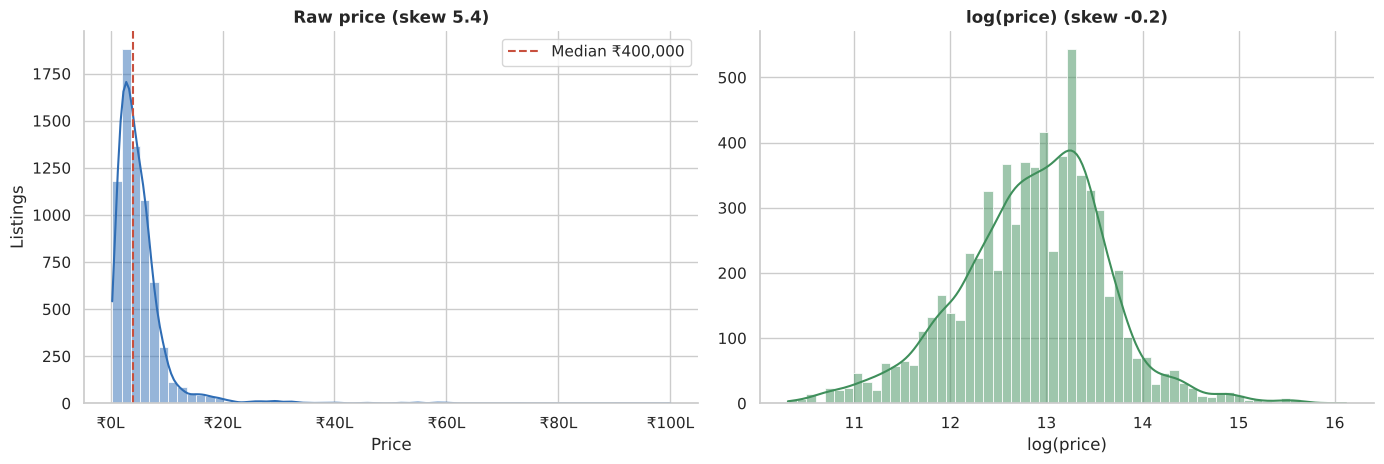

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
sns.histplot(df["price"], bins=60, kde=True, ax=ax[0], color=BLUE)
ax[0].axvline(df.price.median(), color=RED, ls="--", label=f"Median ₹{df.price.median():,.0f}"); ax[0].legend()
ax[0].xaxis.set_major_formatter(lakh); ax[0].set(title=f"Raw price (skew {df.price.skew():.1f})", xlabel="Price", ylabel="Listings")
sns.histplot(df["log_price"], bins=60, kde=True, ax=ax[1], color=GREEN); ax[1].set(title=f"log(price) (skew {df.log_price.skew():.1f})", xlabel="log(price)", ylabel="")
plt.tight_layout(); plt.show()

### EDA 2: How much do prices vary? (violin + quartiles)

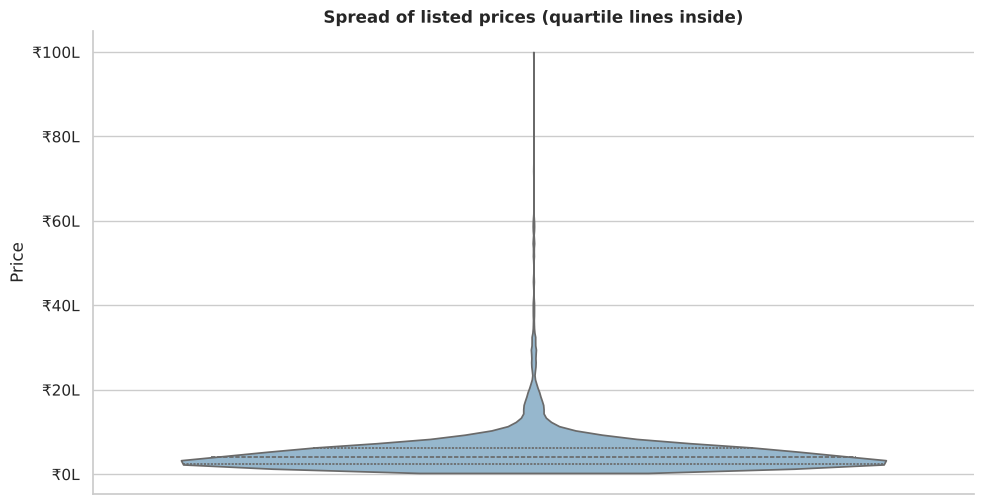

count        6912.0
mean       514535.0
std        506003.0
min         29999.0
25%        250000.0
50%        400000.0
75%        630250.0
95%       1200000.0
max      10000000.0


In [6]:
fig, ax = plt.subplots(figsize=(10, 5.2))
sns.violinplot(data=df, y="price", inner="quartile", cut=0, color="#8DB9D6", ax=ax)
ax.yaxis.set_major_formatter(lakh); ax.set(title="Spread of listed prices (quartile lines inside)", ylabel="Price")
plt.tight_layout(); plt.show()
print(df.price.describe(percentiles=[.25,.5,.75,.95]).round(0).to_string())

### EDA 3: What does the sample consist of? (count plots)

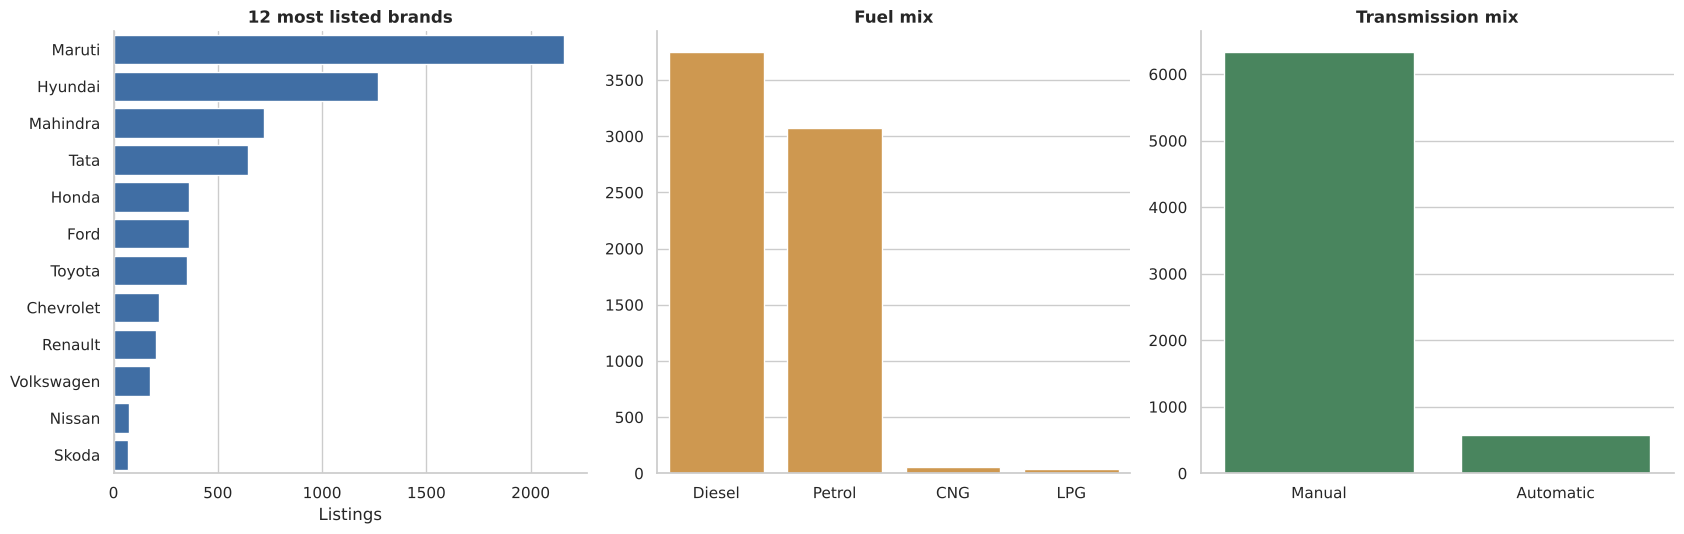

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(17, 5.5))
top = df.brand.value_counts().head(12).index
sns.countplot(data=df[df.brand.isin(top)], y="brand", order=top, ax=ax[0], color=BLUE); ax[0].set(title="12 most listed brands", xlabel="Listings", ylabel="")
sns.countplot(data=df, x="fuel", order=df.fuel.value_counts().index, ax=ax[1], color=ORANGE); ax[1].set(title="Fuel mix", xlabel="", ylabel="")
sns.countplot(data=df, x="transmission", ax=ax[2], color=GREEN); ax[2].set(title="Transmission mix", xlabel="", ylabel="")
plt.tight_layout(); plt.show()

### EDA 4: How do age and mileage relate? (scatter)

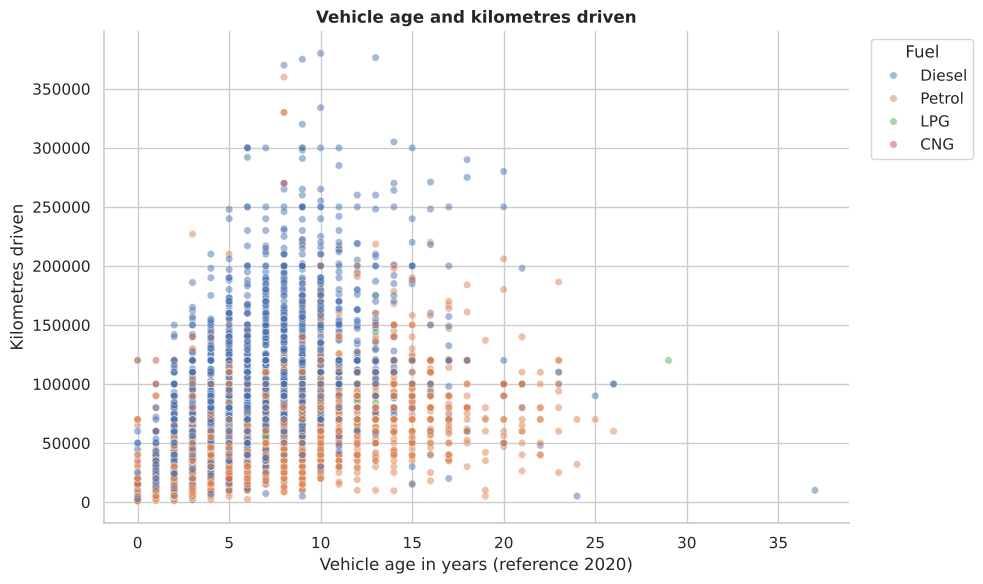

In [8]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(data=df, x="car_age", y="km_driven", hue="fuel", alpha=.5, s=28, ax=ax)
ax.set(title="Vehicle age and kilometres driven", xlabel=f"Vehicle age in years (reference {REF_YEAR})", ylabel="Kilometres driven")
ax.legend(title="Fuel", bbox_to_anchor=(1.02, 1), loc="upper left"); plt.tight_layout(); plt.show()

### EDA 5: Numerical relationships (correlation heatmap)

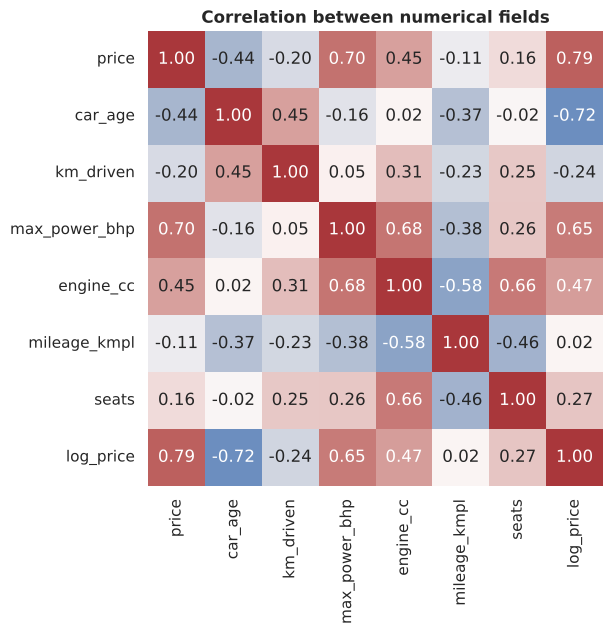

In [9]:
num = df[["price","car_age","km_driven","max_power_bhp","engine_cc","mileage_kmpl","seats"]].copy(); num["log_price"] = df["log_price"]
fig, ax = plt.subplots(figsize=(8.5, 6.5))
sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="vlag", center=0, square=True, ax=ax, cbar=False)
ax.set_title("Correlation between numerical fields"); plt.tight_layout(); plt.show()

**EDA takeaways:** prices are strongly right-skewed (a few luxury cars), power and engine size correlate positively with price, age correlates negatively, and power/engine are highly correlated with each other. Petrol and diesel dominate and most cars are manual.

---
# Part B: Five research objectives
Each objective asks one question, shows a matching chart, and states what it means. Associations only, not causal claims.

## Objective 1: Which brands have the highest and lowest resale prices?

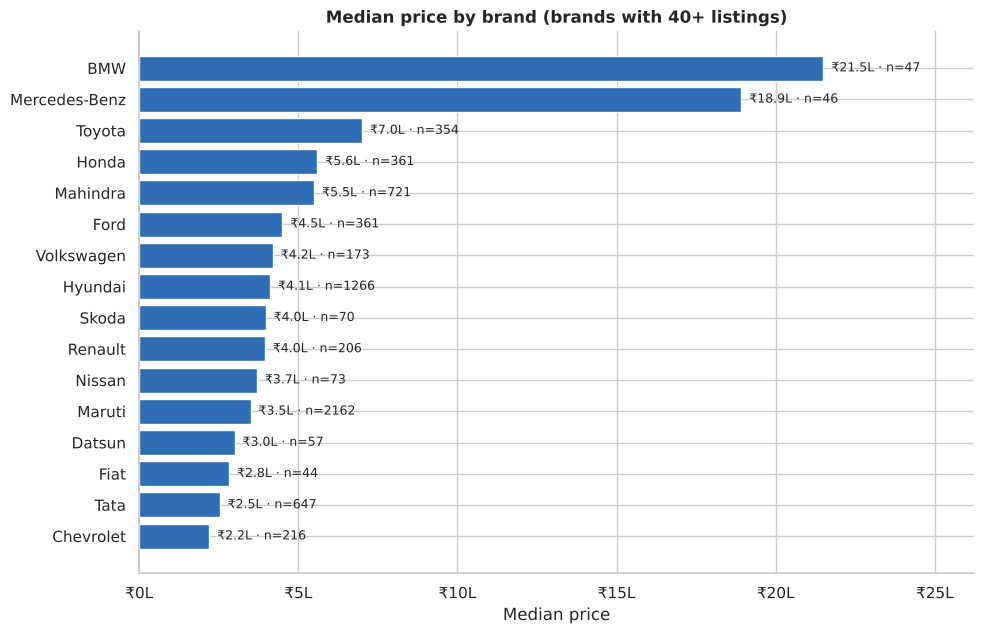

In [10]:
bs = df.groupby("brand").agg(median_price=("price","median"), listings=("price","size")).query("listings >= 40").sort_values("median_price")
fig, ax = plt.subplots(figsize=(10, 6.5))
ax.barh(bs.index, bs.median_price, color=BLUE)
for y, (m, n) in enumerate(zip(bs.median_price, bs.listings)): ax.text(m, y, f"  ₹{m/1e5:.1f}L · n={n}", va="center", fontsize=9)
ax.xaxis.set_major_formatter(lakh); ax.set_xlim(0, bs.median_price.max()*1.22)
ax.set(title="Median price by brand (brands with 40+ listings)", xlabel="Median price", ylabel=""); plt.tight_layout(); plt.show()

**Finding:** luxury brands (BMW, Mercedes-Benz) sit far above mass-market brands; Toyota, Honda and Mahindra form a mid tier; Maruti, Tata and Chevrolet are cheapest. Volume matters: Maruti and Hyundai dominate listings, so their medians are the most reliable.

## Objective 2: How does vehicle age affect price?

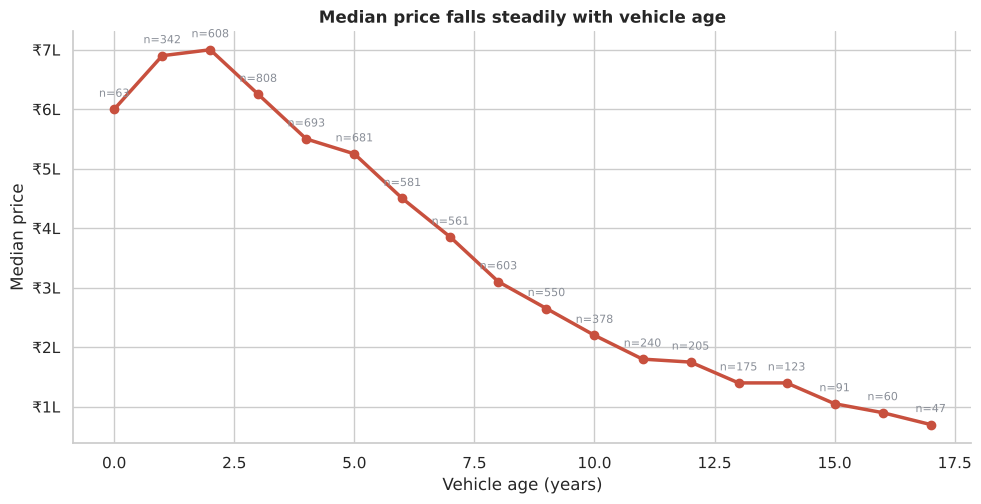

Simple trend: each extra year of age is associated with about 13% lower price (before controlling for brand or power).


In [11]:
age = df.groupby("car_age").agg(median_price=("price","median"), listings=("price","size")).query("listings >= 30")
fig, ax = plt.subplots(figsize=(10, 5.2))
ax.plot(age.index, age.median_price, marker="o", lw=2.5, color=RED)
for a, r in age.iterrows(): ax.annotate(f"n={int(r.listings)}", (a, r.median_price), textcoords="offset points", xytext=(0, 9), ha="center", fontsize=8, color=GREY)
ax.yaxis.set_major_formatter(lakh); ax.set(title="Median price falls steadily with vehicle age", xlabel="Vehicle age (years)", ylabel="Median price")
plt.tight_layout(); plt.show()

slope = np.polyfit(df["car_age"], df["log_price"], 1)[0]
print(f"Simple trend: each extra year of age is associated with about {(1-np.exp(slope))*100:.0f}% lower price (before controlling for brand or power).")

**Finding:** price falls steadily with age, from roughly ₹6–7L for the newest cars to about ₹2L at ten years. The very newest cars are few in number (n shown), so treat the left end cautiously.

## Objective 3: Is higher mileage linked to lower prices?

,median_price,listings
km_band,,
<25k,575000.0,1033
25-50k,480000.0,1571
50-75k,400000.0,1360
75-100k,342500.0,1390
100-150k,325000.0,1186
150k+,325000.0,372


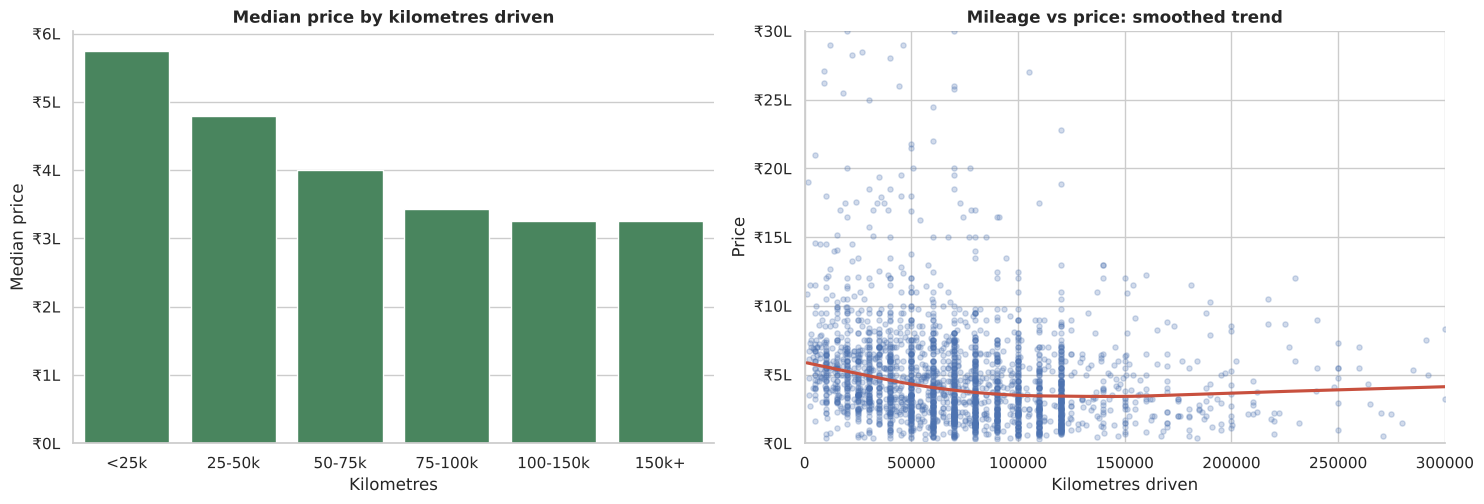

In [12]:
df["km_band"] = pd.cut(df.km_driven, [0, 25_000, 50_000, 75_000, 100_000, 150_000, 400_000], labels=["<25k", "25-50k", "50-75k", "75-100k", "100-150k", "150k+"])
mb = df.groupby("km_band", observed=True).agg(median_price=("price","median"), listings=("price","size"))
display(mb)
fig, ax = plt.subplots(1, 2, figsize=(15, 5.2))
sns.barplot(x=mb.index.astype(str), y=mb.median_price, ax=ax[0], color=GREEN); ax[0].yaxis.set_major_formatter(lakh)
ax[0].set(title="Median price by kilometres driven", xlabel="Kilometres", ylabel="Median price")
sns.regplot(data=df.sample(2500, random_state=SEED), x="km_driven", y="price", lowess=True, scatter_kws={"alpha": .25, "s": 14}, line_kws={"color": RED}, ax=ax[1])
ax[1].yaxis.set_major_formatter(lakh); ax[1].set_xlim(0, 300_000); ax[1].set_ylim(0, 3_000_000)
ax[1].set(title="Mileage vs price: smoothed trend", xlabel="Kilometres driven", ylabel="Price")
plt.tight_layout(); plt.show()

**Finding:** the median price falls as mileage rises, but the relationship is looser than age: cars with similar mileage vary widely in price because brand and power matter more. Mileage and age are also tangled (older cars have driven more).

## Objective 4: How do fuel type and transmission relate to price?

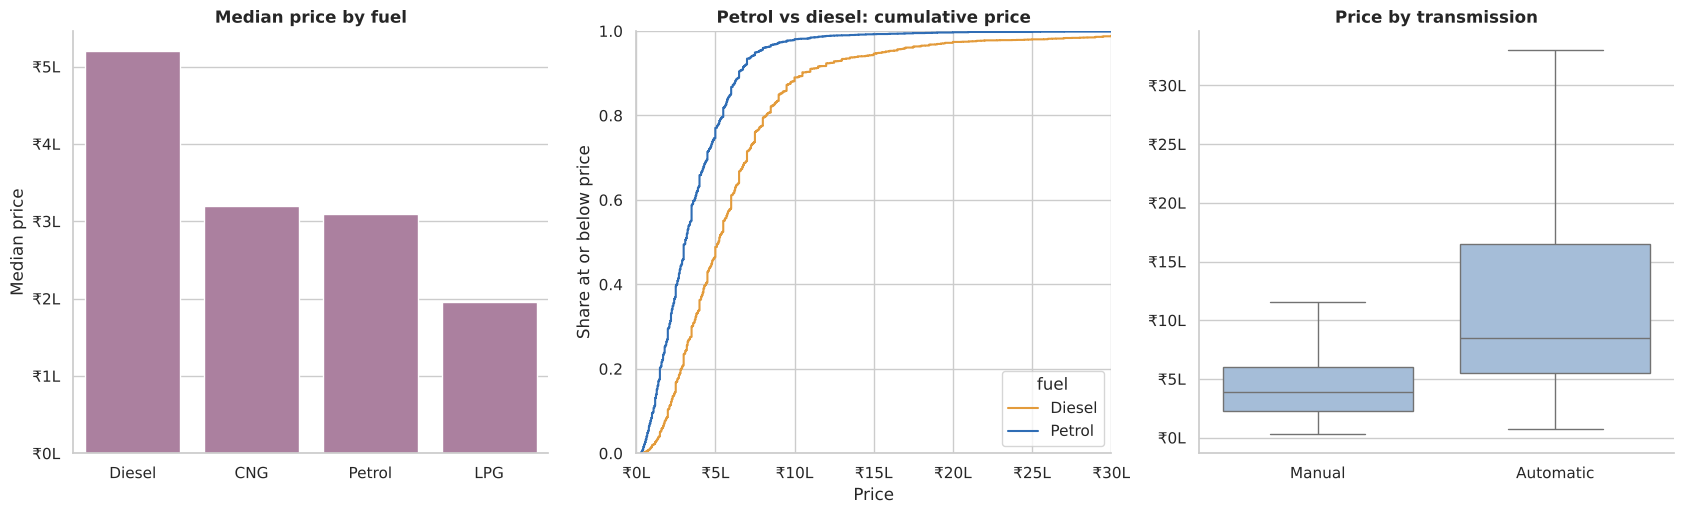

,median_price,listings
fuel,,
CNG,320000.0,55
Diesel,520000.0,3749
LPG,195500.0,38
Petrol,310000.0,3070


In [13]:
fig, ax = plt.subplots(1, 3, figsize=(17, 5.3))
fs = df.groupby("fuel").price.median().sort_values(ascending=False)
sns.barplot(x=fs.index, y=fs.values, ax=ax[0], color="#B279A2"); ax[0].yaxis.set_major_formatter(lakh); ax[0].set(title="Median price by fuel", xlabel="", ylabel="Median price")
sns.ecdfplot(data=df[df.fuel.isin(["Petrol", "Diesel"])], x="price", hue="fuel", ax=ax[1], palette=[ORANGE, BLUE]); ax[1].xaxis.set_major_formatter(lakh); ax[1].set_xlim(0, 3_000_000)
ax[1].set(title="Petrol vs diesel: cumulative price", xlabel="Price", ylabel="Share at or below price")
sns.boxplot(data=df, x="transmission", y="price", showfliers=False, ax=ax[2], color="#9DBDE0"); ax[2].yaxis.set_major_formatter(lakh); ax[2].set(title="Price by transmission", xlabel="", ylabel="")
plt.tight_layout(); plt.show()
display(df.groupby(["fuel"]).agg(median_price=("price","median"), listings=("price","size")).round(0))

**Finding:** diesel cars list higher than petrol, and automatics list far above manuals. Part of this reflects mix: diesel and automatic cars are more often bigger, newer, more powerful cars. CNG and LPG have very few listings, so they are shown but not over-interpreted.

## Objective 5: Do ownership history and seller type affect price?

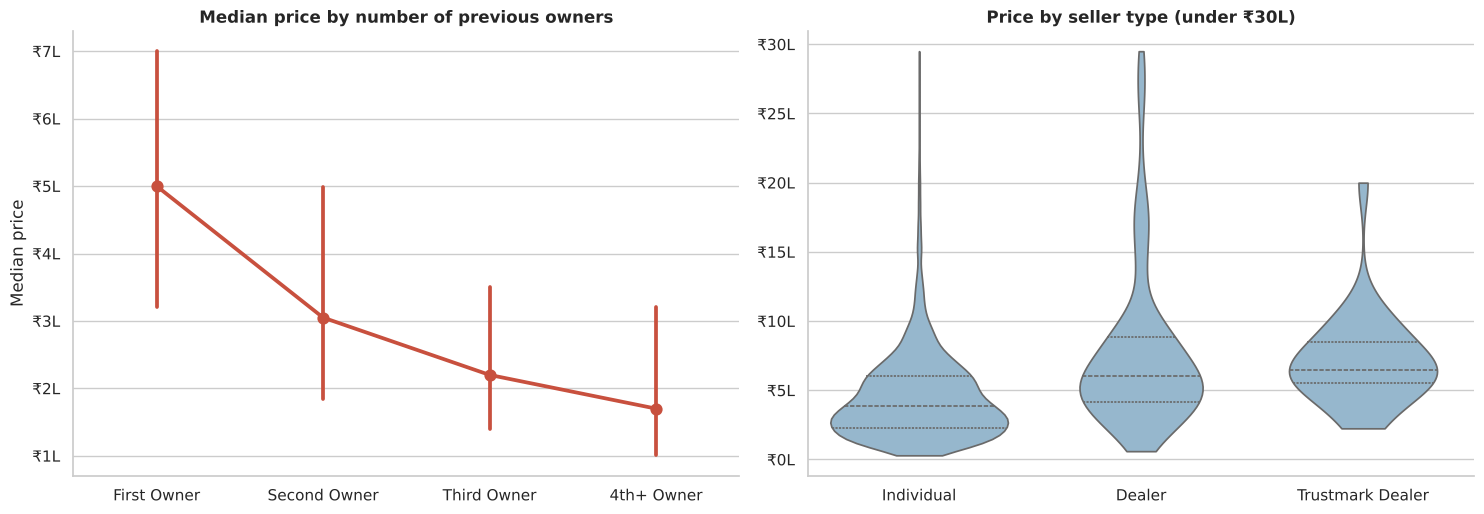

,median_price,median_age,listings
owner,,,
First Owner,500000.0,4.0,4240
Second Owner,305000.0,8.0,1969
Third Owner,220000.0,10.0,535
4th+ Owner,170000.0,12.0,168


In [14]:
order = ["First Owner", "Second Owner", "Third Owner", "4th+ Owner"]
fig, ax = plt.subplots(1, 2, figsize=(15, 5.3))
sns.pointplot(data=df, x="owner", y="price", order=order, estimator=np.median, errorbar=("pi", 50), color=RED, ax=ax[0], linestyles="-")
ax[0].yaxis.set_major_formatter(lakh); ax[0].set(title="Median price by number of previous owners", xlabel="", ylabel="Median price")
sns.violinplot(data=df[df.price < 3_000_000], x="seller_type", y="price", inner="quartile", cut=0, color="#8DB9D6", ax=ax[1])
ax[1].yaxis.set_major_formatter(lakh); ax[1].set(title="Price by seller type (under ₹30L)", xlabel="", ylabel="")
plt.tight_layout(); plt.show()
display(df.groupby("owner").agg(median_price=("price","median"), median_age=("car_age","median"), listings=("price","size")).reindex(order))

**Finding:** median price falls with each extra owner, and dealers list higher than individual sellers. The `median_age` column shows why caution is needed: later-owner cars are also older, so part of the gap is age, not ownership alone.

---
# Part C: Machine-learning classification, finding the best fit among four models

**Prediction task:** classify a listing as **Budget**, **Mid-range** or **Premium** using only listing details. The class boundaries are the 33rd and 67th percentiles of price **in the training set only**, so no information from the test set influences the labels. Price is used only to create the label and is never a predictor.

**Models compared:** Gaussian Naive Bayes · Decision Tree · Random Forest · SVM (RBF kernel).
**Fair comparison:** the same train/test split, the same preprocessing, each model tuned by 5-fold cross-validation on the training set only, and the best model chosen on cross-validated macro-F1. The test set is used once, for the final report.

## 1. Create the target and split the data

In [15]:
num_feats = ["car_age", "km_driven", "mileage_kmpl", "engine_cc", "max_power_bhp", "seats"]
cat_feats = ["brand", "model_family", "fuel", "seller_type", "transmission", "owner"]
X = df[num_feats + cat_feats]
train_idx, test_idx = train_test_split(df.index, test_size=0.2, random_state=SEED)
q1, q2 = df.loc[train_idx, "price"].quantile([1/3, 2/3])
labels = ["Budget", "Mid-range", "Premium"]
y = pd.cut(df["price"], [-np.inf, q1, q2, np.inf], labels=labels).astype(str)
X_train, X_test, y_train, y_test = X.loc[train_idx], X.loc[test_idx], y.loc[train_idx], y.loc[test_idx]
print(f"Class boundaries (from training set): Budget ≤ ₹{q1:,.0f} < Mid-range ≤ ₹{q2:,.0f} < Premium")
print(f"Train {len(X_train):,} | Test {len(X_test):,}")
display(pd.DataFrame({"train": y_train.value_counts(), "test": y_test.value_counts()}).loc[labels])

Class boundaries (from training set): Budget ≤ ₹300,000 < Mid-range ≤ ₹550,000 < Premium
Train 5,529 | Test 1,383


,train,test
price,,
Budget,1958,501
Mid-range,1751,455
Premium,1820,427


## 2. Shared preprocessing

In [16]:
num_pipe = Pipeline([("imp", SimpleImputer(strategy="median")), ("scale", StandardScaler())])
cat_pipe = OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=10, sparse_output=False)
def make_pre(): return ColumnTransformer([("num", num_pipe, num_feats), ("cat", cat_pipe, cat_feats)])

## 3. Tune each model with 5-fold cross-validation (training set only)

In [17]:
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
spaces = {
    "Naive Bayes":   (GaussianNB(), {"m__var_smoothing": [1e-9, 1e-6, 1e-4, 1e-2, 1e-1, 1.0]}),
    "Decision Tree": (DecisionTreeClassifier(random_state=SEED), {"m__max_depth": [3, 5, 7, 10, None], "m__min_samples_leaf": [1, 5, 10, 20]}),
    "Random Forest": (RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED), {"m__max_depth": [10, 20, None], "m__min_samples_leaf": [1, 2, 5], "m__max_features": ["sqrt", 0.3]}),
    "SVM (RBF)":     (SVC(kernel="rbf", probability=True, random_state=SEED), {"m__C": [1, 3, 10, 30], "m__gamma": ["scale", 0.01, 0.003]}),
}
tuned, cv_rows = {}, []
for name, (est, grid) in spaces.items():
    gs = GridSearchCV(Pipeline([("pre", make_pre()), ("m", est)]), grid, cv=cv, scoring="f1_macro", n_jobs=-1).fit(X_train, y_train)
    tuned[name] = gs.best_estimator_
    cv_rows.append({"Model": name, "CV macro-F1 (mean)": gs.best_score_, "CV std": gs.cv_results_["std_test_score"][gs.best_index_],
                    "Best settings": {k.replace("m__", ""): v for k, v in gs.best_params_.items()}})
cv_table = pd.DataFrame(cv_rows).set_index("Model").sort_values("CV macro-F1 (mean)", ascending=False)
pd.set_option("display.max_colwidth", 80); display(cv_table.round(4))

,CV macro-F1 (mean),CV std,Best settings
Model,,,
SVM (RBF),0.8546,0.0057,"{'C': 30, 'gamma': 0.01}"
Random Forest,0.8444,0.0056,"{'max_depth': 10, 'max_features': 0.3, 'min_samples_leaf': 2}"
Decision Tree,0.8123,0.0087,"{'max_depth': 10, 'min_samples_leaf': 1}"
Naive Bayes,0.7341,0.0055,{'var_smoothing': 0.01}


## 4. Evaluate all four on the untouched test set

In [18]:
rows, preds, probas = [], {}, {}
for name, pipe in tuned.items():
    p = pipe.predict(X_test); pr = pipe.predict_proba(X_test); preds[name], probas[name] = p, pr
    rows.append({"Model": name, "Accuracy": accuracy_score(y_test, p),
                 "Precision (macro)": precision_score(y_test, p, average="macro"), "Recall (macro)": recall_score(y_test, p, average="macro"),
                 "F1 (macro)": f1_score(y_test, p, average="macro"),
                 "ROC-AUC (OvR)": roc_auc_score(y_test, pr, multi_class="ovr", labels=pipe.classes_)})
results = pd.DataFrame(rows).set_index("Model").sort_values("F1 (macro)", ascending=False)
display(results.round(3))

,Accuracy,Precision (macro),Recall (macro),F1 (macro),ROC-AUC (OvR)
Model,,,,,
SVM (RBF),0.857,0.859,0.857,0.858,0.964
Random Forest,0.852,0.852,0.852,0.852,0.962
Decision Tree,0.825,0.823,0.825,0.823,0.909
Naive Bayes,0.735,0.736,0.733,0.734,0.890


## 5. Compare performance visually

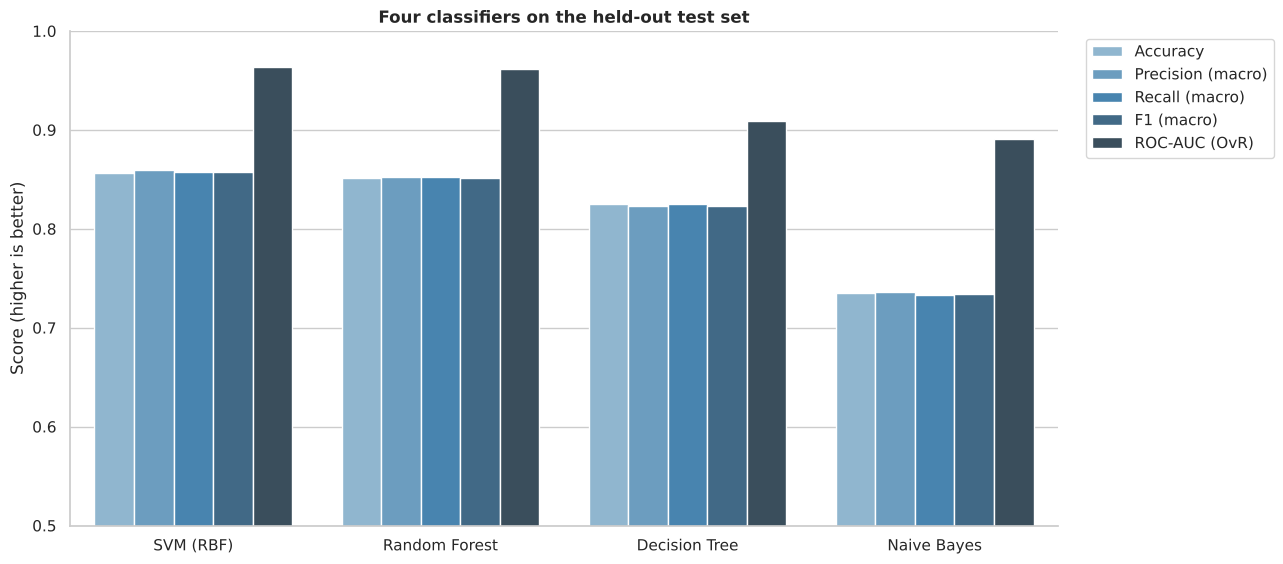

In [19]:
long = results.reset_index().melt(id_vars="Model", var_name="Metric", value_name="Score")
fig, ax = plt.subplots(figsize=(13, 5.8))
sns.barplot(data=long, x="Model", y="Score", hue="Metric", ax=ax, palette="Blues_d")
ax.set(title="Four classifiers on the held-out test set", ylim=(0.5, 1.0), xlabel="", ylabel="Score (higher is better)")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left"); plt.tight_layout(); plt.show()

## 6. Confusion matrices: where does each model go wrong?

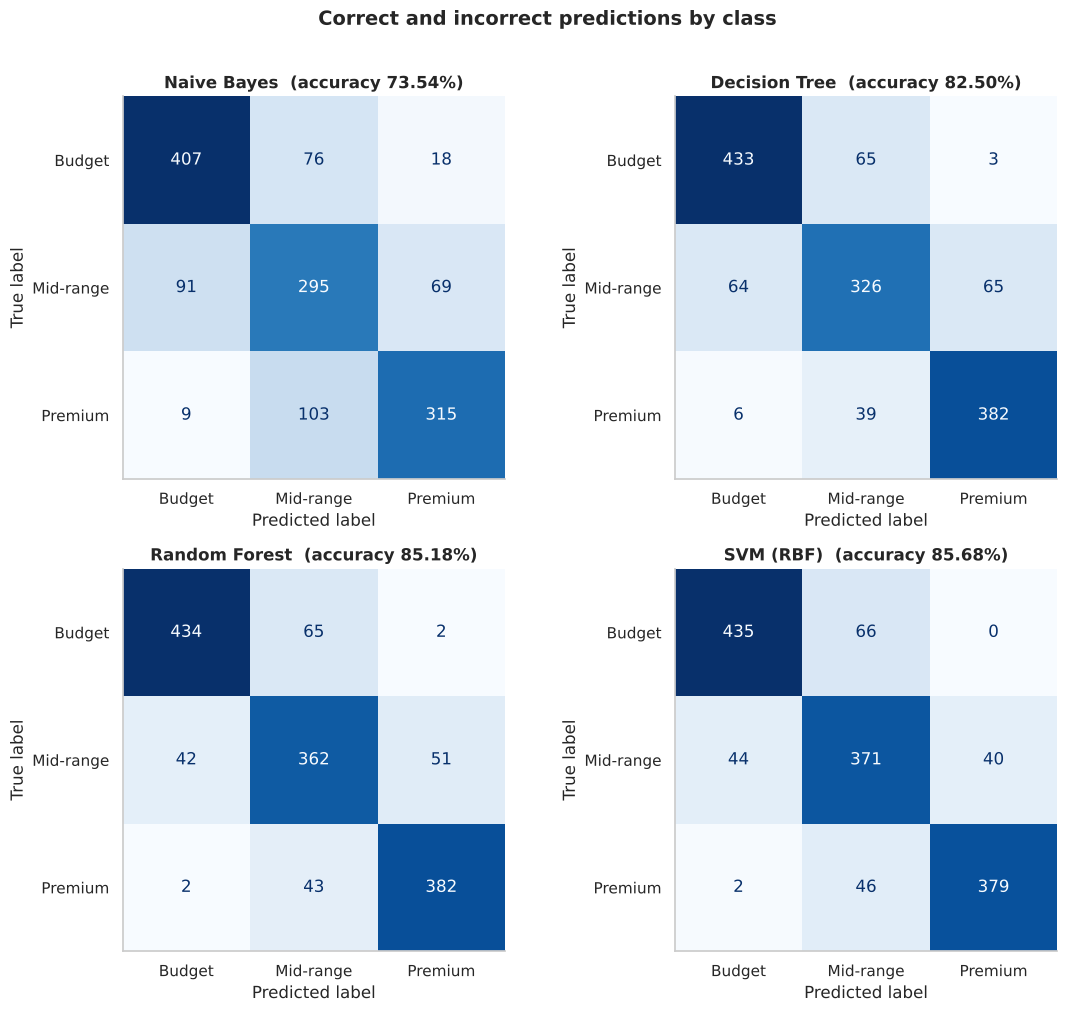

Share of cars misclassified by TWO classes (Budget ↔ Premium), the costly mistake:
Naive Bayes      1.95%
Decision Tree    0.65%
Random Forest    0.29%
SVM (RBF)        0.14%


In [20]:
fig, axes = plt.subplots(2, 2, figsize=(11.5, 10))
for ax, (name, p) in zip(axes.flat, preds.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, p, labels=labels, cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(f"{name}  (accuracy {accuracy_score(y_test, p):.2%})"); ax.grid(False)
plt.suptitle("Correct and incorrect predictions by class", y=1.01, fontweight="bold", fontsize=14); plt.tight_layout(); plt.show()

rank = {l: i for i, l in enumerate(labels)}
far = {n: np.mean(np.abs(y_test.map(rank).values - pd.Series(p).map(rank).values) == 2) for n, p in preds.items()}
print("Share of cars misclassified by TWO classes (Budget ↔ Premium), the costly mistake:")
print(pd.Series(far).mul(100).round(2).astype(str).add("%").to_string())

## 7. Choose the best model

In [21]:
best_name = cv_table.index[0]; best = tuned[best_name]
agree = results.index[0] == best_name
print(f"Best by cross-validated macro-F1: {best_name}")
print(f"Best by test-set macro-F1: {results.index[0]} ({'agrees' if agree else 'differs, see note'})\n")
print(classification_report(y_test, preds[best_name], labels=labels, digits=3))

Best by cross-validated macro-F1: SVM (RBF)
Best by test-set macro-F1: SVM (RBF) (agrees)

              precision    recall  f1-score   support

      Budget      0.904     0.868     0.886       501
   Mid-range      0.768     0.815     0.791       455
     Premium      0.905     0.888     0.896       427

    accuracy                          0.857      1383
   macro avg      0.859     0.857     0.858      1383
weighted avg      0.860     0.857     0.858      1383



## 8. What drives the best model's decisions? (permutation importance)

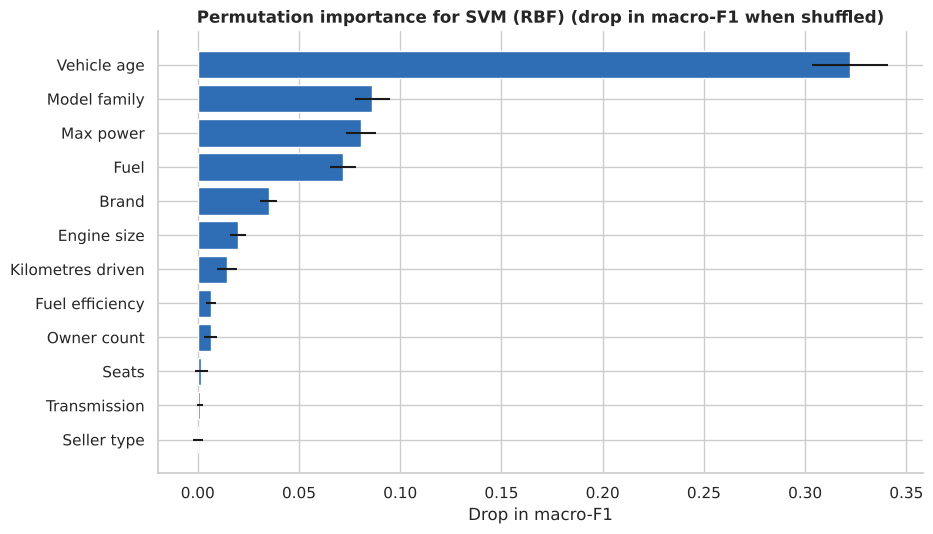

In [22]:
pi = permutation_importance(best, X_test, y_test, scoring="f1_macro", n_repeats=10, random_state=SEED, n_jobs=-1)
names = {"car_age":"Vehicle age","km_driven":"Kilometres driven","mileage_kmpl":"Fuel efficiency","engine_cc":"Engine size","max_power_bhp":"Max power","seats":"Seats",
         "brand":"Brand","model_family":"Model family","fuel":"Fuel","seller_type":"Seller type","transmission":"Transmission","owner":"Owner count"}
imp = pd.DataFrame({"f": [names[c] for c in X_test.columns], "m": pi.importances_mean, "s": pi.importances_std}).sort_values("m")
fig, ax = plt.subplots(figsize=(9.5, 5.5)); ax.barh(imp.f, imp.m, xerr=imp.s, color=BLUE)
ax.set(title=f"Permutation importance for {best_name} (drop in macro-F1 when shuffled)", xlabel="Drop in macro-F1", ylabel=""); plt.tight_layout(); plt.show()

## 9. Decision tree interpretation (first three levels)

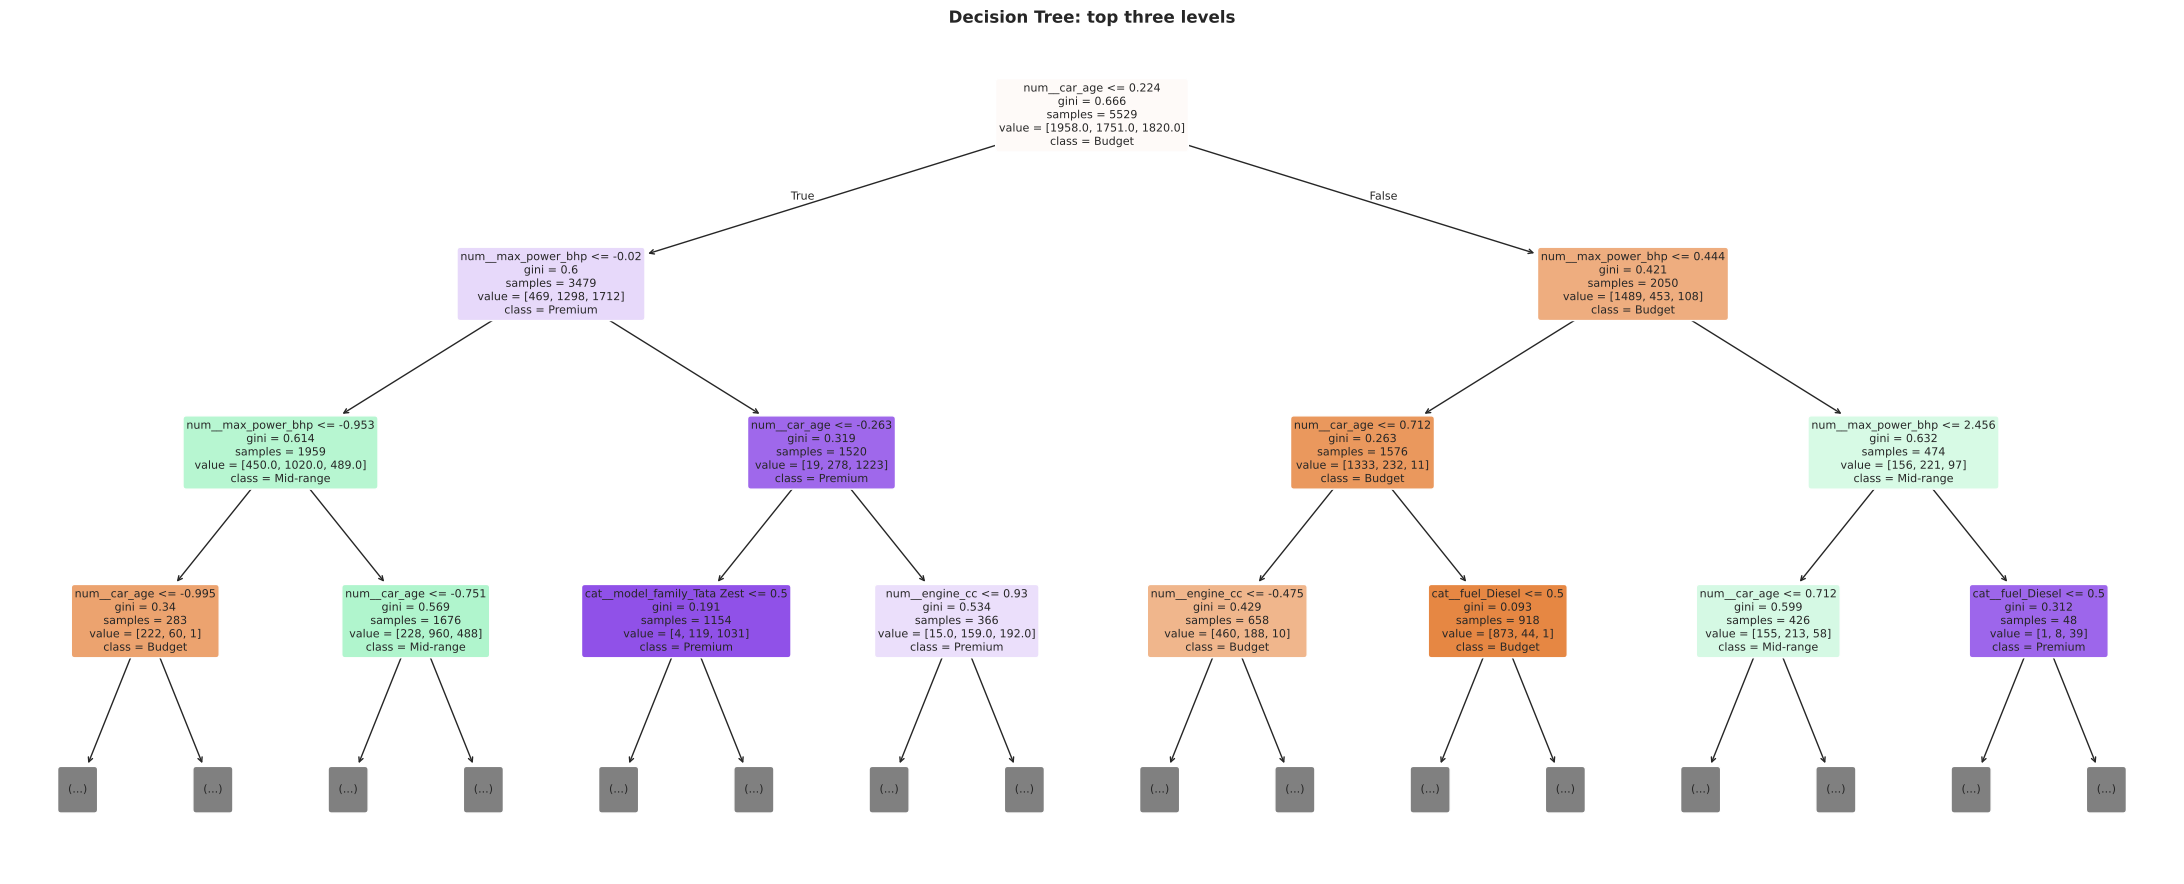

In [23]:
dt = tuned["Decision Tree"]; feat = dt.named_steps["pre"].get_feature_names_out()
fig, ax = plt.subplots(figsize=(22, 9))
plot_tree(dt.named_steps["m"], feature_names=feat, class_names=list(dt.named_steps["m"].classes_), filled=True, rounded=True, max_depth=3, fontsize=8, ax=ax)
ax.set_title("Decision Tree: top three levels"); plt.tight_layout(); plt.show()

## 10. Final results and conclusions

### Model comparison (test set, 1,383 cars never used for tuning)
| Model | Accuracy | Macro-F1 | ROC-AUC | Budget↔Premium errors |
|---|---|---|---|---|
| **SVM (RBF)** | **85.7%** | **0.858** | **0.964** | 0.14% |
| Random Forest | 85.2% | 0.852 | 0.962 | 0.29% |
| Decision Tree | 82.5% | 0.823 | 0.909 | 0.65% |
| Naive Bayes | 73.5% | 0.734 | 0.890 | 1.95% |

**Best fit: SVM (RBF kernel)**, chosen on cross-validated macro-F1 (0.855 ± 0.006) and confirmed on the test set. Random Forest is a close second: the gap is under one percentage point, which is within normal noise, so the honest reading is "SVM and Random Forest are effectively tied, SVM narrowly ahead". Random Forest is the better choice if interpretability or speed matters more than the last half-point of accuracy.

**Why the ranking looks like this**
- **SVM** handles the non-linear boundaries between price classes and copes well with many one-hot brand/model columns once features are scaled.
- **Random Forest** captures the same interactions (brand × age × power) by averaging many trees, and is less sensitive to tuning.
- **Decision Tree** is easy to read but a single tree overfits and is less stable.
- **Naive Bayes** is weakest because it assumes features are independent and roughly Gaussian. Here age, mileage, engine size and power are strongly related, and the one-hot columns are not Gaussian.

**Error pattern:** mistakes are almost all between *neighbouring* classes. The best model confuses Budget with Premium for only 0.14% of cars. Mid-range is the hardest class (F1 0.79) because it sits between the other two.

### What the EDA and objectives showed
1. **EDA:** prices are strongly right-skewed (a few luxury cars), age correlates negatively with price, power and engine size positively, and the sample is dominated by Maruti/Hyundai, petrol/diesel and manual cars.
2. **Brands:** BMW and Mercedes-Benz medians (about ₹19–22L) are several times those of Maruti, Tata and Chevrolet (about ₹2–3.5L).
3. **Age:** the strongest single driver. The simple trend is about 13% lower price per year, and median price falls from roughly ₹6–7L for the newest cars to about ₹2L at ten years.
4. **Mileage:** median price falls from about ₹5.8L (<25k km) to about ₹3.3L (100k+ km), then flattens. The link is looser than age because mileage and age move together.
5. **Fuel and transmission:** diesel (median ₹5.2L) lists well above petrol (₹3.1L), and automatics above manuals. Part of this is mix (bigger, newer, more powerful cars).
6. **Ownership and seller:** median price falls from ₹5.0L (first owner) to ₹1.7L (4th+), but later-owner cars are also older (median age 4 vs 12 years). Dealers list above individual sellers.
7. **Model drivers:** permutation importance shows vehicle age is by far the most important feature, then model family, max power and fuel. Transmission, seats and seller type add almost nothing once those are known.

### Limitations
- Prices are **listing prices** from about 2020, not confirmed sale prices.
- Condition, accident history, service records and location are not in the data, which caps accuracy.
- Price classes are **relative** (training-set terciles), and classification discards exact prices.
- Objective findings are associations in a sample; mix effects (age, power) explain part of every raw gap.
- Results come from one train/test split plus 5-fold cross-validation on the training set; the SVM–Random Forest difference is too small to call a decisive win.

### Next steps
- Predict the actual price (regression) with prediction intervals, not just the class.
- Retrain on current listings to measure how far the 2020 pattern has drifted.
- Add accident history and city if a dataset with those fields is available.